# Face Biometrics End-to-End: Baseline Matcher -> Tuned Cross-Validated System

**Task.** Build, train and evaluate a complete *face recognition* biometric system on the
AT&T / ORL **"Olivetti faces"** database (40 subjects x 10 images, 64x64 greyscale, 1992-94).

**Why this dataset.** It downloads automatically through scikit-learn (no registration form,
no Kaggle token), the whole notebook re-runs on a laptop CPU in a few minutes, and exactly
10 images per subject makes stratified k-fold over 40 classes come out perfectly balanced.
Everything here transfers unchanged to a larger corpus (LFW, CASIA-WebFace, a fingerprint or
iris set) by swapping the loader in Part 1.

---

### Two things people mean by "biometric accuracy"

A biometric system is evaluated in two *different* regimes, and mixing them up is the single
most common mistake in student projects and in papers:

| | **Identification (1:N)** | **Verification (1:1)** |
|---|---|---|
| Question | "Who is this person?" | "Is this person who they claim to be?" |
| Output | One identity out of N enrolled | Accept / reject a claimed identity |
| Natural metrics | Accuracy, precision, recall, confusion matrix, **CMC / rank-k** | **ROC, AUC, EER, FAR/FRR, DET** |
| Failure mode | Confusing subject A with subject B | Letting an impostor in / locking a genuine user out |

A third regime matters in deployment and is usually skipped entirely:

* **Closed-set** identification assumes every probe belongs to someone enrolled.
* **Open-set** identification must also *reject* people who were never enrolled. This is what
  a real access-control system does, and accuracy alone cannot measure it.

This notebook reports **all three**.

---

### Notebook structure

| Part | Content |
|---|---|
| 0 | Configuration, seeds, reproducibility |
| 1 | Download the dataset if it is not already cached |
| 2 | **Basic** preparation: flatten + a single stratified hold-out split |
| 3 | **Basic** model: Eigenfaces (PCA) + nearest-template matcher |
| 4 | Shared evaluation toolkit (written once, used by every model) |
| 5 | Evaluate the baseline: confusion matrix, ROC/AUC, accuracy / precision / recall, CMC |
| 6 | Verification view of the baseline: genuine vs impostor, EER, FAR/FRR, DET |
| 7 | **Better** preparation: stratified k-fold + in-fold augmentation (no leakage) |
| 8 | **Better** model: PCA(whitened) -> LDA (Fisherfaces) -> RBF-SVM, hyperparameters tuned in a nested grid search |
| 9 | Evaluate the improved model on out-of-fold predictions (same toolkit) |
| 10 | Open-set identification: rejecting people who were never enrolled |
| 11 | Error analysis: eigenfaces, hardest subjects, misclassified probes |
| 12 | Model comparison, deployment cost (template size + matching latency), saving the model |
| 13 | Limitations, privacy / template-protection notes, extensions |

## Part 0 - Configuration and reproducibility

Every knob that changes the experiment lives in this one cell, so the rest of the notebook
stays declarative. Seeding matters more than usual here: biometric operating points (EER in
particular) move by a noticeable margin between runs on a dataset this small, so an unseeded
notebook produces numbers you cannot defend.

In [1]:
# If anything is missing:  pip install numpy scipy scikit-learn matplotlib pandas joblib
import os
import sys
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

from sklearn.base import clone
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, auc, balanced_accuracy_score,
                             confusion_matrix, pairwise_distances,
                             precision_recall_fscore_support, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
import joblib

# ---------------------------------------------------------------- reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)           # all stochastic steps draw from this generator

# ---------------------------------------------------------------- paths
DATA_HOME = Path("./data")                  # dataset cache (download target)
FIG_DIR   = Path("./figures")               # every figure is also written to disk
MODEL_DIR = Path("./models")                # trained model + metadata
for d in (DATA_HOME, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- experiment settings
TEST_FRACTION   = 0.30     # Part 2 hold-out: 3 of the 10 images per subject become probes
N_SPLITS        = 5        # Part 7 stratified k-fold (5 x 80 probes = every image scored once)
N_AUG           = 2        # Part 7: 2 extra augmented copies per training image (3x data)
N_KNOWN_OPENSET = 32       # Part 10: 32 enrolled identities, 8 held out as impostors
FAST_MODE       = False    # True -> shrink the hyperparameter grid and skip augmentation

# Hyperparameter grid searched *inside* each training fold (nested CV -> unbiased estimate)
PARAM_GRID = ({"svm__C": [10.0], "svm__gamma": ["scale"]} if FAST_MODE else
              {"pca__n_components": [120],
               "svm__C":            [1.0, 10.0, 100.0],
               "svm__gamma":        ["scale", 0.005]})

# Plot styling
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "font.size": 9, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.constrained_layout.use": True})   # keeps suptitles clear

# LDA warns about collinear features on small face datasets; it is expected, not a bug.
warnings.filterwarnings("ignore", message=".*Variables are collinear.*")

def savefig(fig, name):
    """Persist a figure next to the notebook so it can go straight into a report."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    return path

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
import sklearn; print(f"scikit-learn {sklearn.__version__}")
print(f"seed={SEED} | fast_mode={FAST_MODE} | data_home={DATA_HOME.resolve()}")

python      3.13.5
numpy       2.1.3
scikit-learn 1.6.1
seed=42 | fast_mode=False | data_home=/Users/bli1/Documents/project/lab/lab-practice/biometrics/data


## Part 1 - Download the dataset (only if it is not already there)

`fetch_olivetti_faces` writes a single `olivetti.pkz` cache into `data_home`. We check for
that file first so the download happens exactly once; every later run is offline.

The loader also carries an **offline fallback**: if the machine has no network access it
synthesises a structurally similar dataset (40 identities x 10 samples of 64x64 images with
per-identity structure plus pose/illumination jitter) so the full pipeline still runs and can
be demonstrated. That fallback is clearly flagged and is *not* a substitute for real
biometric data - absolute numbers from it mean nothing.

In [2]:
def _make_synthetic_faces(n_subjects=40, n_per_subject=10, size=64, rng=None):
    """
    OFFLINE FALLBACK ONLY. Builds a toy dataset with the same shape and the same statistical
    structure as a face database: each identity gets a fixed smooth "template" (a random sum
    of Gaussian blobs), and each sample of that identity is the template plus small shifts,
    brightness/contrast change and sensor noise -- i.e. within-class variation that is smaller
    than between-class variation, which is exactly the property a biometric relies on.
    """
    rng = rng or np.random.default_rng(SEED)
    yy, xx = np.mgrid[0:size, 0:size] / size
    images, labels = [], []
    for subject in range(n_subjects):
        template = np.zeros((size, size))
        for _ in range(8):                                     # 8 random blobs per identity
            cx, cy = rng.uniform(0.15, 0.85, 2)
            sigma  = rng.uniform(0.06, 0.20)
            amp    = rng.uniform(-1.0, 1.0)
            template += amp * np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * sigma ** 2)))
        template = (template - template.min()) / (np.ptp(template) + 1e-8)
        for _ in range(n_per_subject):
            sample = ndimage.shift(template, rng.uniform(-2, 2, 2), order=1, mode="nearest")
            sample = sample * rng.uniform(0.85, 1.15) + rng.uniform(-0.08, 0.08)
            sample = sample + rng.normal(0, 0.02, sample.shape)
            images.append(np.clip(sample, 0, 1).astype(np.float32))
            labels.append(subject)
    return np.asarray(images, dtype=np.float32), np.asarray(labels, dtype=int)


def load_face_dataset(data_home=DATA_HOME, allow_synthetic_fallback=True):
    """
    Download-if-missing loader.

    Returns
    -------
    images : (n_samples, 64, 64) float32 in [0, 1]   -- kept 2-D for augmentation / display
    labels : (n_samples,) int                        -- subject id, the biometric "identity"
    source : str                                     -- "olivetti" or "synthetic-fallback"
    """
    data_home = Path(data_home)
    data_home.mkdir(parents=True, exist_ok=True)
    cache = data_home / "olivetti.pkz"

    if cache.exists():
        print(f"[cache] {cache} already present ({cache.stat().st_size/1e6:.2f} MB) "
              f"-- skipping download")
    else:
        print(f"[download] {cache} not found -- fetching the Olivetti/ORL face database ...")

    try:
        bundle = fetch_olivetti_faces(data_home=str(data_home), shuffle=False,
                                      download_if_missing=True)
        return bundle.images.astype(np.float32), bundle.target.astype(int), "olivetti"
    except Exception as exc:                                    # no network, proxy, 404 ...
        if not allow_synthetic_fallback:
            raise
        print(f"[warning] real dataset unavailable ({type(exc).__name__}: {exc})")
        print("[warning] falling back to SYNTHETIC data -- pipeline is valid, "
              "the numbers are not real biometric performance.")
        imgs, lbls = _make_synthetic_faces(rng=np.random.default_rng(SEED))
        return imgs, lbls, "synthetic-fallback"


images, y, DATA_SOURCE = load_face_dataset()
X = images.reshape(len(images), -1)          # (n_samples, 4096) flat feature vectors
CLASSES = np.unique(y)                       # sorted identity labels -- used everywhere below
H, W = images.shape[1], images.shape[2]

[download] data/olivetti.pkz not found -- fetching the Olivetti/ORL face database ...


In [3]:
# ---- Sanity / integrity check: never trust a dataset you have not looked at -----------
counts = np.bincount(y, minlength=len(CLASSES))
print(f"source              : {DATA_SOURCE}")
print(f"images              : {images.shape}  dtype={images.dtype}")
print(f"flattened features  : {X.shape[1]} ({H}x{W} pixels)")
print(f"identities (classes): {len(CLASSES)}")
print(f"samples per identity: min={counts.min()}  max={counts.max()}  "
      f"-> {'perfectly balanced' if counts.min() == counts.max() else 'IMBALANCED'}")
print(f"pixel range         : [{X.min():.3f}, {X.max():.3f}]  mean={X.mean():.3f}")
print(f"NaN / Inf           : {np.isnan(X).sum()} / {np.isinf(X).sum()}")

# Exact-duplicate check: duplicated rows across a train/test split silently inflate accuracy.
n_unique_rows = len(np.unique(X, axis=0))
print(f"duplicate images    : {len(X) - n_unique_rows}")
assert counts.min() >= 2, "need >=2 samples per identity to both enrol and probe"

source              : olivetti
images              : (400, 64, 64)  dtype=float32
flattened features  : 4096 (64x64 pixels)
identities (classes): 40
samples per identity: min=10  max=10  -> perfectly balanced
pixel range         : [0.000, 1.000]  mean=0.547
NaN / Inf           : 0 / 0
duplicate images    : 0


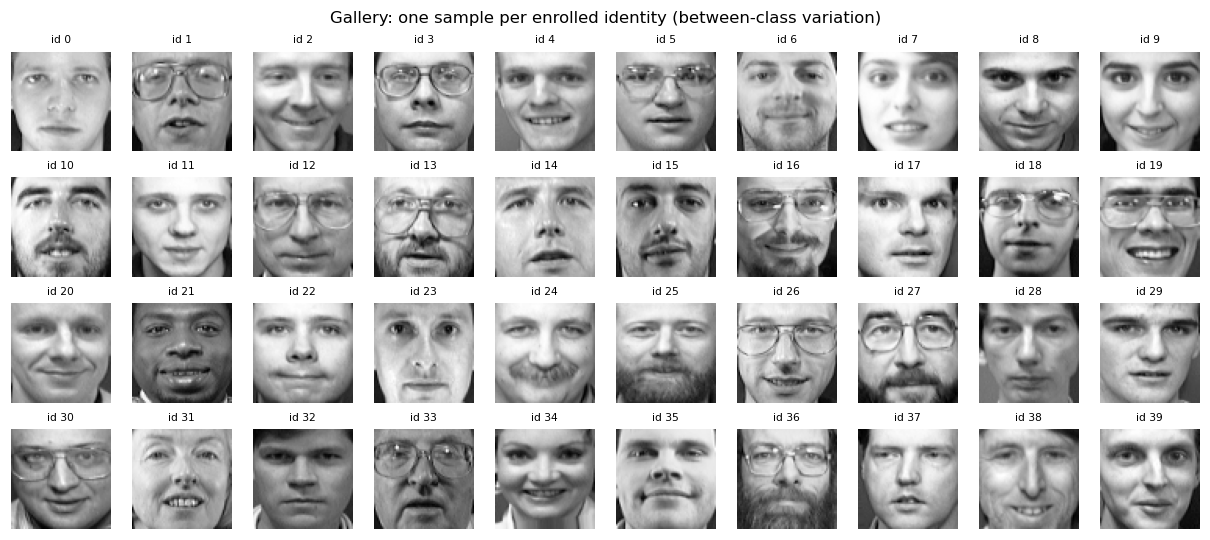

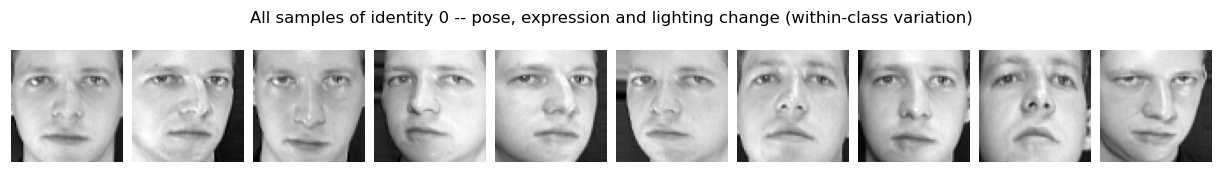

In [4]:
# ---- Look at the data: one image per identity, then the within-class variation ---------
fig, axes = plt.subplots(4, 10, figsize=(11, 4.8))
for i, ax in enumerate(axes.ravel()):
    if i < len(CLASSES):
        ax.imshow(images[np.flatnonzero(y == CLASSES[i])[0]], cmap="gray")
        ax.set_title(f"id {CLASSES[i]}", fontsize=7)
    ax.axis("off")
fig.suptitle("Gallery: one sample per enrolled identity (between-class variation)")
savefig(fig, "01_gallery_identities"); plt.show()

subject = CLASSES[0]
rows = np.flatnonzero(y == subject)
fig, axes = plt.subplots(1, len(rows), figsize=(11, 1.6))
for ax, r in zip(np.atleast_1d(axes), rows):
    ax.imshow(images[r], cmap="gray"); ax.axis("off")
fig.suptitle(f"All samples of identity {subject} -- pose, expression and lighting change "
             f"(within-class variation)")
savefig(fig, "02_within_class_variation"); plt.show()

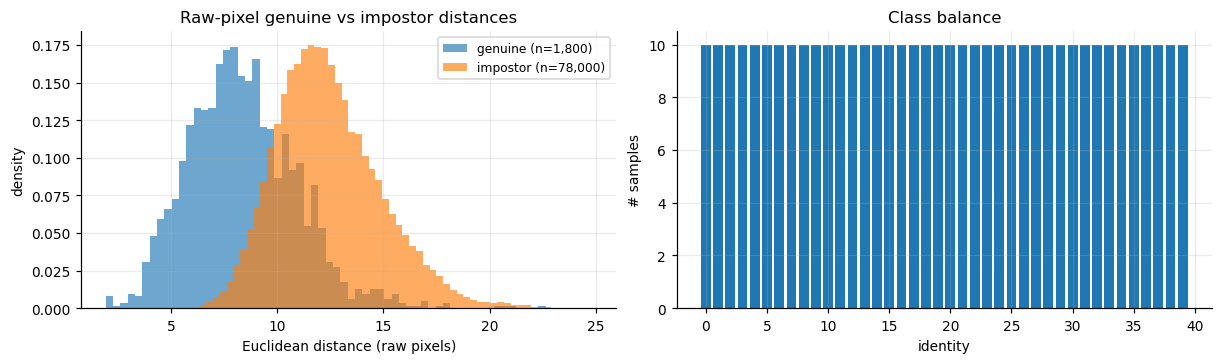

raw-pixel d-prime (separation, more negative = genuine closer): -1.61
The two histograms overlap heavily -> raw pixels are a poor biometric template. That overlap is what PCA/LDA below is for.


In [5]:
# ---- Separability preview -------------------------------------------------------------
# A biometric only works if the within-class (genuine) distances are systematically smaller
# than the between-class (impostor) distances. Checking this on RAW PIXELS before modelling
# tells us how much work the feature extractor actually has to do.
D_raw = pairwise_distances(X, metric="euclidean")
same = (y[:, None] == y[None, :])
triu = np.triu(np.ones_like(same, dtype=bool), k=1)
gen_raw, imp_raw = D_raw[same & triu], D_raw[~same & triu]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(gen_raw, bins=60, alpha=0.65, density=True, label=f"genuine (n={gen_raw.size:,})")
axes[0].hist(imp_raw, bins=60, alpha=0.65, density=True, label=f"impostor (n={imp_raw.size:,})")
axes[0].set_xlabel("Euclidean distance (raw pixels)"); axes[0].set_ylabel("density")
axes[0].set_title("Raw-pixel genuine vs impostor distances"); axes[0].legend(fontsize=8)

axes[1].bar(CLASSES, counts, color="tab:blue")
axes[1].set_xlabel("identity"); axes[1].set_ylabel("# samples")
axes[1].set_title("Class balance")
savefig(fig, "03_raw_separability"); plt.show()

overlap = (gen_raw.mean() - imp_raw.mean()) / np.sqrt(0.5 * (gen_raw.var() + imp_raw.var()))
print(f"raw-pixel d-prime (separation, more negative = genuine closer): {overlap:.2f}")
print("The two histograms overlap heavily -> raw pixels are a poor biometric template. "
      "That overlap is what PCA/LDA below is for.")

## Part 2 - Basic dataset preparation

The deliberately simple version: flatten each image to a 4096-dim vector and cut **one**
stratified hold-out split, 7 images per subject for enrolment and 3 for probing.

Three things that are easy to get wrong and are handled explicitly here:

1. **Stratify.** With 40 classes and 400 samples, an unstratified split can leave a subject
   with zero enrolment images - that subject then becomes unrecognisable by construction.
2. **Fit the scaler on the training half only.** `StandardScaler` learns per-pixel mean and
   variance. Fitting it on all 400 images leaks probe statistics into the template and
   inflates every number that follows. This is the most common leak in face-recognition code.
3. **Know which protocol you are running.** This is a *subject-inclusive* split: the same
   identities appear in enrolment and probe sets, different images. That is correct for
   closed-set **identification**. For a verification system that must generalise to people it
   has never seen, you want a *subject-disjoint* split - Part 10 does exactly that.

In [6]:
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(y)),
    test_size=TEST_FRACTION,
    stratify=y,                 # guarantees every identity appears in both halves
    random_state=SEED,
)

print(f"enrolment (train): {X_train.shape[0]:>3} samples "
      f"({X_train.shape[0] // len(CLASSES)} per identity)")
print(f"probe     (test) : {X_test.shape[0]:>3} samples "
      f"({X_test.shape[0] // len(CLASSES)} per identity)")
print(f"identities present in both halves: "
      f"{len(set(y_train) & set(y_test))} / {len(CLASSES)}")

# No index may appear on both sides -- cheap assertion, catches a whole class of bugs.
assert not (set(idx_train) & set(idx_test)), "train/test index overlap -> data leakage"

enrolment (train): 280 samples (7 per identity)
probe     (test) : 120 samples (3 per identity)
identities present in both halves: 40 / 40


## Part 3 - Basic model: Eigenfaces + nearest-template matcher

The textbook baseline (Turk & Pentland, 1991), kept intentionally plain:

1. **Standardise** pixels (fit on enrolment data only).
2. **PCA to 80 components** - the *eigenfaces*. 4096 -> 80 dimensions removes the dominant
   illumination directions and makes distances meaningful. `whiten=True` equalises the
   variance of each component so one high-variance direction cannot dominate the metric.
3. **Match by nearest enrolled template.** For a probe $p$ and identity $c$, the match score is

   $$s(p, c) \;=\; -\min_{g \in \mathcal{G}_c} \lVert z_p - z_g \rVert_2$$

   the negative distance to the *closest* enrolled template of that identity.

That score matrix is the right output shape for a biometric system, and it is what makes the
rest of this notebook possible: `argmax` over identities gives **identification**, the sorted
order gives the **CMC curve**, and thresholding individual scores gives **verification**.
A classifier that only returns a hard label cannot do the last two.

In [7]:
def nearest_template_scores(Z_gallery, y_gallery, Z_probe, classes, metric="euclidean"):
    """
    Core biometric matcher: probe x identity match-score matrix.

    Score(probe, identity c) = -(distance to the closest enrolled template of c).
    Higher score = better match. Returns (n_probe, n_classes).
    """
    D = pairwise_distances(Z_probe, Z_gallery, metric=metric)      # (n_probe, n_gallery)
    S = np.full((Z_probe.shape[0], len(classes)), -np.inf, dtype=float)
    for i, c in enumerate(classes):
        mask = (y_gallery == c)
        if mask.any():
            S[:, i] = -D[:, mask].min(axis=1)
    return S


# ---- Fit the baseline feature extractor (enrolment data only) -------------------------
baseline_tf = Pipeline([
    ("scaler", StandardScaler()),
    ("pca",    PCA(n_components=80, whiten=True, svd_solver="randomized",
                   random_state=SEED)),
])

t0 = time.perf_counter()
Z_train_base = baseline_tf.fit_transform(X_train)       # enrolled templates
baseline_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
Z_test_base = baseline_tf.transform(X_test)             # probe templates
S_base = nearest_template_scores(Z_train_base, y_train, Z_test_base, CLASSES)
baseline_match_time = time.perf_counter() - t0

y_pred_base = CLASSES[S_base.argmax(axis=1)]            # 1:N identification decision

evr = baseline_tf.named_steps["pca"].explained_variance_ratio_.sum()
print(f"template dimension      : {Z_train_base.shape[1]} (from {X.shape[1]} pixels)")
print(f"variance retained by PCA: {evr:.1%}")
print(f"enrolment time          : {baseline_fit_time*1000:.0f} ms")
print(f"matching time           : {baseline_match_time*1000:.0f} ms "
      f"for {len(X_test)} probes")
print(f"score matrix            : {S_base.shape} (probes x identities)")

template dimension      : 80 (from 4096 pixels)
variance retained by PCA: 92.9%
enrolment time          : 107 ms
matching time           : 3 ms for 120 probes
score matrix            : (120, 40) (probes x identities)


## Part 4 - Shared evaluation toolkit

Written once, called for every model. Keeping the evaluation code in one place is what makes
the baseline-vs-improved comparison in Part 12 meaningful - both models go through literally
the same function calls.

**What each metric answers**

* **Accuracy** - fraction of probes identified correctly. Fine here because classes are
  balanced; with 1000 users and one of them appearing 500 times it is useless.
* **Precision (macro)** - when the system claims "this is subject $c$", how often is it right,
  averaged equally over subjects. In access control this is the quantity tied to *false
  accepts*.
* **Recall (macro)** - of the probes that really are subject $c$, how many were found,
  averaged over subjects. Tied to *false rejects* - the metric users complain about.
* **Macro vs weighted** - macro averages per-class, so a single subject the system never
  recognises is clearly visible. Weighted averages by support and hides exactly that.
* **Confusion matrix** - *which* subjects get mixed up. Row-normalised so each row is "where
  did probes of this subject actually go".
* **ROC / AUC (one-vs-rest)** - threshold-free quality of the *scores*, not of the hard
  decision. A model can be accurate and still have badly ordered scores, which breaks any
  system that needs a confidence threshold.
* **CMC / rank-k** - the biometric-specific one. In forensic use an operator reviews a short
  candidate list, so "the right person was in the top 5" is the operational question.

In [8]:
# ======================================================================================
#  IDENTIFICATION (1:N) METRICS
# ======================================================================================
def topk_accuracy(y_true, S, classes, k):
    """Rank-k identification rate: is the true identity inside the top-k candidate list?"""
    true_col = np.searchsorted(classes, y_true)
    topk = np.argsort(-S, axis=1)[:, :k]
    return float(np.mean((topk == true_col[:, None]).any(axis=1)))


def identification_metrics(y_true, y_pred, S=None, classes=None):
    """Accuracy / precision / recall / F1 in both macro and weighted form, plus rank-k."""
    out = {"accuracy":          accuracy_score(y_true, y_pred),
           "balanced_accuracy": balanced_accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=avg,
                                                      zero_division=0)
        out[f"precision_{avg}"] = p
        out[f"recall_{avg}"]    = r
        out[f"f1_{avg}"]        = f1
    if S is not None and classes is not None:
        out["rank1_accuracy"] = topk_accuracy(y_true, S, classes, 1)
        out["rank5_accuracy"] = topk_accuracy(y_true, S, classes, 5)
    return out


def print_metrics(name, m):
    print("-" * 78)
    print(f"  {name}")
    print("-" * 78)
    print(f"  accuracy           {m['accuracy']:.4f}      "
          f"balanced accuracy  {m['balanced_accuracy']:.4f}")
    print(f"  precision (macro)  {m['precision_macro']:.4f}      "
          f"precision (weighted) {m['precision_weighted']:.4f}")
    print(f"  recall    (macro)  {m['recall_macro']:.4f}      "
          f"recall    (weighted) {m['recall_weighted']:.4f}")
    print(f"  F1        (macro)  {m['f1_macro']:.4f}      "
          f"F1        (weighted) {m['f1_weighted']:.4f}")
    if "rank5_accuracy" in m:
        print(f"  rank-1             {m['rank1_accuracy']:.4f}      "
              f"rank-5             {m['rank5_accuracy']:.4f}")


# ======================================================================================
#  CONFUSION MATRIX
# ======================================================================================
def plot_confusion(y_true, y_pred, classes, title, normalize=True, save=None):
    """Row-normalised confusion matrix + the worst off-diagonal confusions in text."""
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    disp = cm.astype(float)
    if normalize:
        rowsum = disp.sum(axis=1, keepdims=True)
        rowsum[rowsum == 0] = 1.0
        disp = disp / rowsum

    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    im = ax.imshow(disp, cmap="viridis", vmin=0, vmax=1 if normalize else disp.max())
    fig.colorbar(im, ax=ax, fraction=0.046,
                 label="fraction of this identity's probes" if normalize else "count")
    step = max(1, len(classes) // 20)
    ax.set_xticks(range(0, len(classes), step)); ax.set_yticks(range(0, len(classes), step))
    ax.set_xticklabels(classes[::step], fontsize=7)
    ax.set_yticklabels(classes[::step], fontsize=7)
    ax.set_xlabel("predicted identity"); ax.set_ylabel("true identity")
    ax.set_title(title); ax.grid(False)
    if len(classes) <= 15:                     # annotate only when it stays readable
        for i in range(len(classes)):
            for j in range(len(classes)):
                if disp[i, j] > 0:
                    ax.text(j, i, f"{disp[i, j]:.2f}", ha="center", va="center",
                            fontsize=6, color="w" if disp[i, j] < 0.6 else "k")
    if save:
        savefig(fig, save)
    plt.show()

    off = cm.copy(); np.fill_diagonal(off, 0)
    pairs = np.dstack(np.unravel_index(np.argsort(-off, axis=None), off.shape))[0]
    worst = [(classes[i], classes[j], off[i, j]) for i, j in pairs[:5] if off[i, j] > 0]
    if worst:
        print("Most frequent confusions (true -> predicted, count):")
        for t, p, n in worst:
            print(f"   id {t:>3}  ->  id {p:>3}   x{n}")
    else:
        print("No off-diagonal errors.")
    return cm


# ======================================================================================
#  ROC / AUC  (one-vs-rest, multi-class)
# ======================================================================================
def plot_multiclass_roc(y_true, S, classes, title, save=None):
    """
    One-vs-rest ROC. Reports BOTH averages because they answer different questions:
      micro -- pools every (probe, identity) decision; dominated by frequent classes.
      macro -- averages the per-identity AUCs; a single badly-modelled subject shows up.
    Raw match scores are used directly, so this works for distances and probabilities alike.
    """
    Y = label_binarize(y_true, classes=classes)
    grid = np.linspace(0, 1, 1001)
    tpr_sum, per_class_auc, n_valid = np.zeros_like(grid), {}, 0

    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    for i, c in enumerate(classes):
        pos = Y[:, i].sum()
        if pos == 0 or pos == len(y_true):
            continue
        fpr_c, tpr_c, _ = roc_curve(Y[:, i], S[:, i])
        per_class_auc[int(c)] = auc(fpr_c, tpr_c)
        tpr_sum += np.interp(grid, fpr_c, tpr_c)
        n_valid += 1
        ax.plot(fpr_c, tpr_c, color="grey", alpha=0.12, lw=0.7)

    macro_tpr = tpr_sum / max(n_valid, 1); macro_tpr[0] = 0.0
    macro_auc = float(np.mean(list(per_class_auc.values())))
    fpr_mi, tpr_mi, _ = roc_curve(Y.ravel(), S.ravel())
    micro_auc = auc(fpr_mi, tpr_mi)

    ax.plot(grid, macro_tpr, lw=2.2, color="tab:blue", label=f"macro-average (AUC {macro_auc:.4f})")
    ax.plot(fpr_mi, tpr_mi, lw=1.8, color="tab:orange", ls="--",
            label=f"micro-average (AUC {micro_auc:.4f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=8); ax.set_xlim(-0.01, 1)
    if save:
        savefig(fig, save)
    plt.show()

    worst = sorted(per_class_auc.items(), key=lambda kv: kv[1])[:3]
    print(f"macro AUC {macro_auc:.4f} | micro AUC {micro_auc:.4f} | "
          f"hardest identities: " + ", ".join(f"id {c} ({a:.3f})" for c, a in worst))
    return {"macro_auc": macro_auc, "micro_auc": micro_auc, "per_class_auc": per_class_auc}


# ======================================================================================
#  CMC  (cumulative match characteristic -- the biometric ranking curve)
# ======================================================================================
def plot_cmc(y_true, S, classes, title, save=None):
    """Rank-k identification rate for every k. CMC(1) == rank-1 accuracy."""
    order    = np.argsort(-S, axis=1)
    true_col = np.searchsorted(classes, y_true)
    ranks    = np.argmax(order == true_col[:, None], axis=1) + 1
    ks       = np.arange(1, len(classes) + 1)
    rates    = np.array([(ranks <= k).mean() for k in ks])

    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    ax.plot(ks, rates, marker="o", ms=3, lw=1.6)
    ax.axhline(1.0, color="grey", ls=":", lw=1)
    ax.set_xlabel("rank k"); ax.set_ylabel("identification rate")
    ax.set_title(title); ax.set_ylim(min(0.5, rates[0] - 0.05), 1.01)
    for k in (1, 5):
        ax.annotate(f"rank-{k}: {rates[k-1]:.3f}", (k, rates[k-1]),
                    textcoords="offset points", xytext=(8, -12), fontsize=8)
    if save:
        savefig(fig, save)
    plt.show()
    print(f"rank-1 {rates[0]:.4f} | rank-5 {rates[4]:.4f} | "
          f"mean rank of the true identity {ranks.mean():.2f}")
    return ranks, rates

In [9]:
# ======================================================================================
#  VERIFICATION (1:1) METRICS -- EER, FAR/FRR, DET
# ======================================================================================
def verification_scores(y_true, S, classes):
    """
    Turn an identification score matrix into a verification experiment.

    Every cell of the matrix is one 1:1 comparison:
      * cell on the true identity  -> GENUINE attempt  (the user is who they claim)
      * every other cell           -> IMPOSTOR attempt (someone claiming another identity)

    n_probes x 1 genuine scores and n_probes x (n_classes - 1) impostor scores.
    """
    mask_genuine = label_binarize(y_true, classes=classes).astype(bool)
    return S[mask_genuine], S[~mask_genuine]


def compute_eer(fpr, tpr, thresholds):
    """Equal Error Rate: the operating point where FAR == FRR. The headline biometric number."""
    fnr = 1.0 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[i] + fnr[i]) / 2.0), float(thresholds[i])


def plot_verification(genuine, impostor, title, save=None):
    """Four-panel verification report: score distributions, ROC, FAR/FRR sweep, DET."""
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones_like(genuine), np.zeros_like(impostor)])
    fpr, tpr, thr = roc_curve(labels, scores)
    roc_auc  = auc(fpr, tpr)
    fnr      = 1.0 - tpr
    eer, eer_threshold = compute_eer(fpr, tpr, thr)
    dprime = (genuine.mean() - impostor.mean()) / np.sqrt(
        0.5 * (genuine.var() + impostor.var()) + 1e-12)
    frr_at_far = {t: float(np.interp(t, fpr, fnr)) for t in (0.10, 0.01, 0.001)}

    fig, ax = plt.subplots(2, 2, figsize=(11, 7))

    # (a) where the two populations sit -- the picture every biometric paper opens with
    ax[0, 0].hist(impostor, bins=80, density=True, alpha=0.6,
                  label=f"impostor (n={impostor.size:,})", color="tab:red")
    ax[0, 0].hist(genuine, bins=40, density=True, alpha=0.7,
                  label=f"genuine (n={genuine.size:,})", color="tab:green")
    ax[0, 0].axvline(eer_threshold, color="k", ls="--", lw=1.2, label="EER threshold")
    ax[0, 0].set_xlabel("match score"); ax[0, 0].set_ylabel("density")
    ax[0, 0].set_title(f"(a) Genuine vs impostor scores  (d' = {dprime:.2f})")
    ax[0, 0].legend(fontsize=8)

    # (b) ROC with the EER point marked
    ax[0, 1].plot(fpr, tpr, lw=2, color="tab:blue", label=f"ROC (AUC {roc_auc:.4f})")
    ax[0, 1].plot([0, 1], [0, 1], "k:", lw=1)
    ax[0, 1].plot(eer, 1 - eer, "ro", ms=7, label=f"EER = {eer*100:.2f}%")
    ax[0, 1].set_xlabel("FAR (false accept rate)"); ax[0, 1].set_ylabel("1 - FRR (genuine accept)")
    ax[0, 1].set_title("(b) Verification ROC"); ax[0, 1].legend(loc="lower right", fontsize=8)

    # (c) the operating-point chooser: pick a threshold for the security level you need
    ax[1, 0].plot(thr, fpr, label="FAR (impostor accepted)", color="tab:red")
    ax[1, 0].plot(thr, fnr, label="FRR (genuine rejected)", color="tab:green")
    ax[1, 0].axvline(eer_threshold, color="k", ls="--", lw=1.2)
    ax[1, 0].axhline(eer, color="grey", ls=":", lw=1)
    ax[1, 0].set_xlabel("decision threshold"); ax[1, 0].set_ylabel("error rate")
    ax[1, 0].set_title("(c) FAR / FRR vs threshold"); ax[1, 0].legend(fontsize=8)
    ax[1, 0].set_ylim(-0.02, 1.02)

    # (d) DET curve -- log-log; this is how biometric results are conventionally reported
    eps = 1e-6
    ax[1, 1].plot(np.clip(fpr, eps, 1), np.clip(fnr, eps, 1), lw=2, color="tab:purple")
    ax[1, 1].plot([eps, 1], [eps, 1], "k:", lw=1)
    ax[1, 1].plot(max(eer, eps), max(eer, eps), "ro", ms=7)
    ax[1, 1].set_xscale("log"); ax[1, 1].set_yscale("log")
    ax[1, 1].set_xlabel("FAR"); ax[1, 1].set_ylabel("FRR")
    ax[1, 1].set_title("(d) DET curve")

    fig.suptitle(title)
    if save:
        savefig(fig, save)
    plt.show()

    print(f"  EER            {eer*100:6.2f}%   (threshold {eer_threshold:.4f})")
    print(f"  verification AUC {roc_auc:.4f}   d-prime {dprime:.2f}")
    for t, v in frr_at_far.items():
        print(f"  FRR @ FAR={t*100:5.1f}% : {v*100:6.2f}%")
    return {"eer": eer, "eer_threshold": eer_threshold, "verification_auc": roc_auc,
            "dprime": float(dprime), "frr_at_far": frr_at_far}


RESULTS = {}      # every model drops its headline numbers here for the Part 12 comparison

## Part 5 - Evaluate the baseline (identification)

------------------------------------------------------------------------------
  BASELINE  Eigenfaces(80) + nearest template  [single hold-out split]
------------------------------------------------------------------------------
  accuracy           0.9083      balanced accuracy  0.9083
  precision (macro)  0.9387      precision (weighted) 0.9388
  recall    (macro)  0.9083      recall    (weighted) 0.9083
  F1        (macro)  0.9059      F1        (weighted) 0.9059
  rank-1             0.9083      rank-5             0.9583


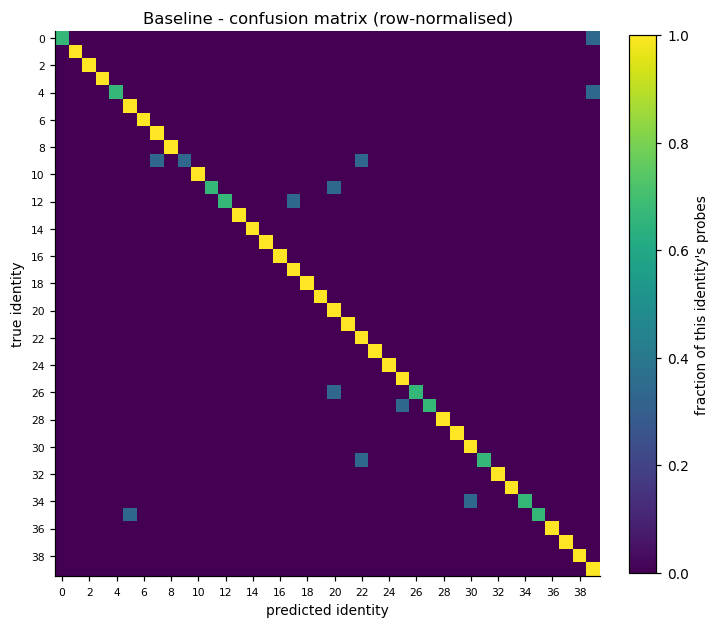

Most frequent confusions (true -> predicted, count):
   id  31  ->  id  22   x1
   id   9  ->  id  22   x1
   id  26  ->  id  20   x1
   id   9  ->  id   7   x1
   id  12  ->  id  17   x1


In [10]:
m_base = identification_metrics(y_test, y_pred_base, S_base, CLASSES)
print_metrics("BASELINE  Eigenfaces(80) + nearest template  [single hold-out split]", m_base)

cm_base = plot_confusion(y_test, y_pred_base, CLASSES,
                         "Baseline - confusion matrix (row-normalised)",
                         save="04_baseline_confusion")

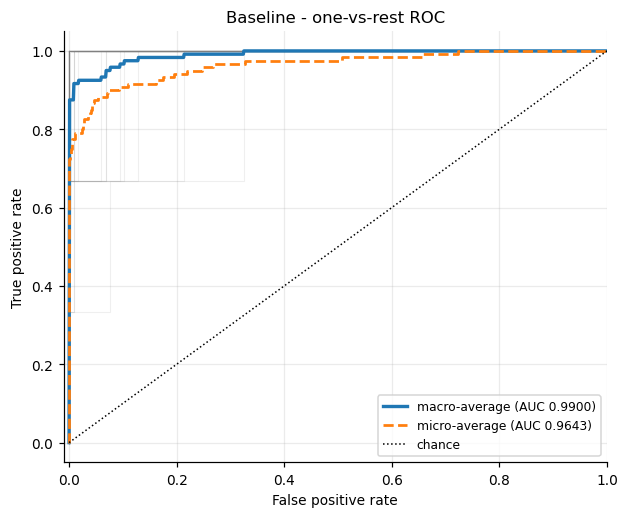

macro AUC 0.9900 | micro AUC 0.9643 | hardest identities: id 31 (0.892), id 35 (0.929), id 9 (0.940)


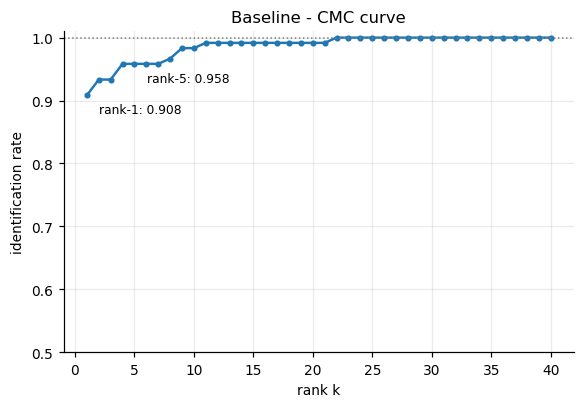

rank-1 0.9083 | rank-5 0.9583 | mean rank of the true identity 1.55


In [11]:
roc_base = plot_multiclass_roc(y_test, S_base, CLASSES,
                               "Baseline - one-vs-rest ROC",
                               save="05_baseline_roc")

ranks_base, cmc_base = plot_cmc(y_test, S_base, CLASSES,
                                "Baseline - CMC curve",
                                save="06_baseline_cmc")

## Part 6 - Evaluate the baseline (verification)

Same scores, different question. A deployed system has to pick a threshold, and the
threshold is where the security/usability trade-off actually lives: raise it and impostors
are kept out but legitimate users get locked out; lower it and the opposite. The **EER** is
the conventional single-number summary, but the honest way to quote a system is *FRR at a
fixed FAR* - a bank cares about FAR = 0.1%, a phone unlock cares about FRR.

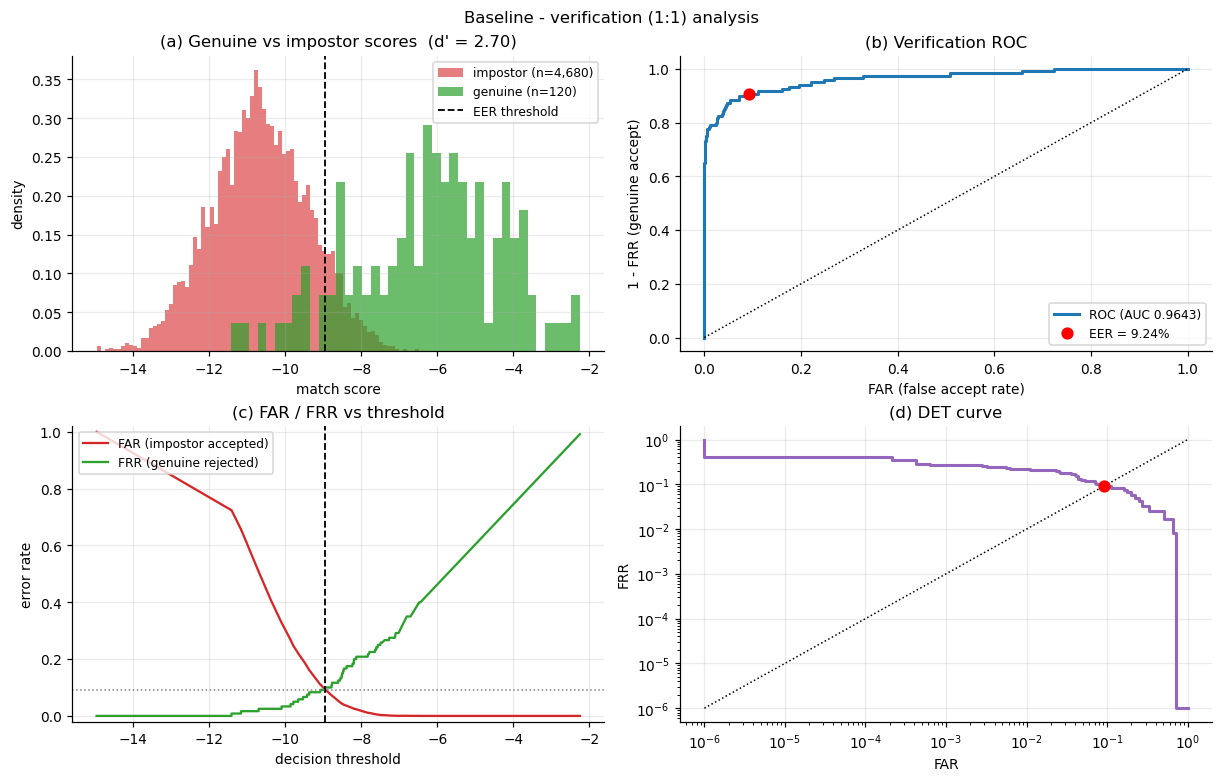

  EER              9.24%   (threshold -8.9532)
  verification AUC 0.9643   d-prime 2.70
  FRR @ FAR= 10.0% :   9.17%
  FRR @ FAR=  1.0% :  22.50%
  FRR @ FAR=  0.1% :  27.50%


In [12]:
gen_base, imp_base = verification_scores(y_test, S_base, CLASSES)
ver_base = plot_verification(gen_base, imp_base,
                             "Baseline - verification (1:1) analysis",
                             save="07_baseline_verification")

RESULTS["Baseline (Eigenfaces + 1-NN, hold-out)"] = {**m_base, **roc_base, **ver_base}

## Part 7 - Better dataset preparation: stratified k-fold + in-fold augmentation

Two problems with Part 2 that are worth being precise about:

**1. A single split on 120 probes is noisy.** One extra error moves accuracy by 0.83
percentage points. Changing `random_state` alone can swing the result by several points, so a
single hold-out number is not something you can compare two models with.
**Stratified 5-fold** fixes this: every one of the 400 images is used as a probe exactly once,
against a model that never saw it. The resulting *out-of-fold* (OOF) predictions form one
complete 400-probe evaluation set, and the per-fold spread gives an honest error bar.

**2. 7 enrolment images per subject is not much.** Augmentation manufactures plausible extra
enrolment samples - small rotations, shifts, mirroring, brightness and contrast change, sensor
noise - which is a direct proxy for the pose/illumination variation a real capture device sees.

> **The leakage trap.** Augmentation must happen *inside* the training fold. If you augment
> first and split afterwards, a rotated copy of a probe image sits in the training set and the
> model is effectively tested on data it memorised. Published face-recognition results have
> been retracted over exactly this. The loop below augments `X[train_idx]` only, and never
> touches `X[test_idx]`.

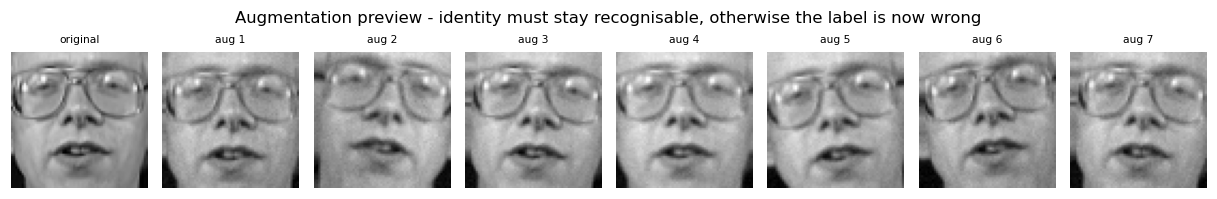

In [13]:
def augment_batch(imgs, labels, n_aug=2, rng=None):
    """
    Produce `n_aug` jittered copies of every image (originals are kept).

    Each transform is a physically plausible capture variation, which is the test for whether
    an augmentation is legitimate: rotation/shift = head pose and framing, horizontal flip =
    mirrored capture (faces are roughly symmetric), gain/bias = illumination, Gaussian noise =
    sensor noise. CALL THIS ON TRAINING DATA ONLY.
    """
    rng = rng or np.random.default_rng(SEED)
    out_imgs, out_lbls = [imgs], [labels]
    for _ in range(n_aug):
        batch = np.empty_like(imgs)
        for i, im in enumerate(imgs):
            t = im[:, ::-1] if rng.random() < 0.5 else im              # mirror
            t = ndimage.rotate(t, rng.uniform(-8, 8), reshape=False,   # head pose
                               order=1, mode="nearest")
            t = ndimage.shift(t, rng.uniform(-2.5, 2.5, 2),            # framing
                              order=1, mode="nearest")
            t = t * rng.uniform(0.85, 1.15) + rng.uniform(-0.06, 0.06) # illumination
            t = t + rng.normal(0, 0.012, t.shape)                      # sensor noise
            batch[i] = np.clip(t, 0.0, 1.0)
        out_imgs.append(batch)
        out_lbls.append(labels)
    return np.concatenate(out_imgs).astype(np.float32), np.concatenate(out_lbls)


# ---- Visual check: never ship an augmentation you have not looked at ------------------
demo_src = images[np.flatnonzero(y == CLASSES[1])[:1]]
demo_aug, _ = augment_batch(demo_src, np.array([CLASSES[1]]), n_aug=7,
                            rng=np.random.default_rng(SEED))
fig, axes = plt.subplots(1, len(demo_aug), figsize=(11, 1.7))
for j, (ax, im) in enumerate(zip(axes, demo_aug)):
    ax.imshow(im, cmap="gray"); ax.axis("off")
    ax.set_title("original" if j == 0 else f"aug {j}", fontsize=7)
fig.suptitle("Augmentation preview - identity must stay recognisable, "
             "otherwise the label is now wrong")
savefig(fig, "08_augmentation_preview"); plt.show()

## Part 8 - Better model: PCA(whitened) -> LDA (Fisherfaces) -> RBF-SVM

Three changes over the baseline, each fixing a specific weakness:

| Stage | What it adds |
|---|---|
| **PCA(whitened, 120)** | Same denoising as before, slightly wider, and whitening makes the following LDA well-conditioned. |
| **LDA (Fisherfaces)** | PCA is *unsupervised* - it maximises total variance, which on faces is dominated by illumination, not identity. LDA uses the labels and maximises the between-subject to within-subject scatter ratio. This is the single biggest win, and the reason Fisherfaces beat Eigenfaces (Belhumeur et al., 1997). Output is 39-D (`n_classes - 1`). |
| **RBF-SVM** | A nearest-template rule draws piecewise-linear boundaries around enrolled samples. An RBF-SVM fits a maximum-margin non-linear boundary, which generalises better from few samples per class, and `probability=True` yields calibrated scores for thresholding. |

**Nested cross-validation.** `C` and `gamma` are selected by an inner 3-fold grid search that
only ever sees the *outer* training fold. Tuning on the data you then report on is optimistic
by a few points - with 400 samples that is easily the difference between a real improvement
and a measurement artefact.

One efficiency note: the inner search runs with `probability=False` (selection only needs the
ranking), and Platt scaling is switched on just for the final per-fold refit.

In [14]:
def build_improved_pipeline(probability=False):
    """Fisherfaces + RBF-SVM. Every stateful step is inside the Pipeline, so cross_val /
    GridSearchCV refit it from scratch on each training fold -- no statistics can leak."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("pca",    PCA(n_components=120, whiten=True, svd_solver="randomized",
                       random_state=SEED)),
        ("lda",    LinearDiscriminantAnalysis(solver="svd")),
        ("svm",    SVC(kernel="rbf", C=10.0, gamma="scale", class_weight="balanced",
                       probability=probability, random_state=SEED)),
    ])


skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_pred  = np.empty(len(y), dtype=int)                    # out-of-fold decisions
oof_score = np.zeros((len(y), len(CLASSES)), dtype=float)   # out-of-fold score matrix
fold_rows, fold_params = [], []
rng_aug = np.random.default_rng(SEED)
t_start = time.perf_counter()

for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
    # -- 1. augment the TRAINING fold only ------------------------------------------------
    if N_AUG > 0 and not FAST_MODE:
        img_tr, y_tr = augment_batch(images[tr], y[tr], n_aug=N_AUG, rng=rng_aug)
        X_tr = img_tr.reshape(len(img_tr), -1)
    else:
        X_tr, y_tr = X[tr], y[tr]
    X_te, y_te = X[te], y[te]                               # untouched, unaugmented probes

    # -- 2. inner grid search for C / gamma (never sees X_te) ------------------------------
    search = GridSearchCV(build_improved_pipeline(probability=False), PARAM_GRID,
                          cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                          scoring="accuracy", n_jobs=-1, refit=False)
    search.fit(X_tr, y_tr)

    # -- 3. refit the winner on the whole training fold, this time with probabilities ------
    model = build_improved_pipeline(probability=True)
    model.set_params(**{**search.best_params_, "svm__probability": True})
    model.fit(X_tr, y_tr)

    # -- 4. score the held-out probes -----------------------------------------------------
    P = model.predict_proba(X_te)
    oof_score[np.ix_(te, np.searchsorted(CLASSES, model.classes_))] = P
    oof_pred[te] = model.classes_[P.argmax(axis=1)]

    acc = accuracy_score(y_te, oof_pred[te])
    fold_rows.append({"fold": fold, "n_train": len(X_tr), "n_test": len(X_te),
                      "accuracy": acc, "inner_cv_best": search.best_score_})
    fold_params.append(search.best_params_)
    print(f"fold {fold}/{N_SPLITS}  train={len(X_tr):>4}  probes={len(X_te):>3}  "
          f"acc={acc:.4f}  best={search.best_params_}")

print(f"\ntotal cross-validation time: {time.perf_counter() - t_start:.1f} s")
fold_df = pd.DataFrame(fold_rows)
print(fold_df.to_string(index=False))
print(f"\naccuracy across folds: {fold_df['accuracy'].mean():.4f} "
      f"+/- {fold_df['accuracy'].std(ddof=1):.4f} (std)")

fold 1/5  train= 960  probes= 80  acc=1.0000  best={'pca__n_components': 120, 'svm__C': 1.0, 'svm__gamma': 'scale'}
fold 2/5  train= 960  probes= 80  acc=0.9875  best={'pca__n_components': 120, 'svm__C': 10.0, 'svm__gamma': 'scale'}
fold 3/5  train= 960  probes= 80  acc=0.9750  best={'pca__n_components': 120, 'svm__C': 1.0, 'svm__gamma': 'scale'}
fold 4/5  train= 960  probes= 80  acc=0.9875  best={'pca__n_components': 120, 'svm__C': 1.0, 'svm__gamma': 'scale'}
fold 5/5  train= 960  probes= 80  acc=1.0000  best={'pca__n_components': 120, 'svm__C': 10.0, 'svm__gamma': 'scale'}

total cross-validation time: 9.9 s
 fold  n_train  n_test  accuracy  inner_cv_best
    1      960      80    1.0000       0.962500
    2      960      80    0.9875       0.975000
    3      960      80    0.9750       0.979167
    4      960      80    0.9875       0.976042
    5      960      80    1.0000       0.981250

accuracy across folds: 0.9900 +/- 0.0105 (std)


## Part 9 - Evaluate the improved model

The numbers below come from **out-of-fold predictions**: every one of the 400 images was
scored by a model trained without it. That is a 400-probe evaluation instead of 120, and the
per-fold standard deviation above is the error bar that belongs next to it.

------------------------------------------------------------------------------
  IMPROVED  PCA->LDA->RBF-SVM  [5-fold out-of-fold, 2x augmentation]
------------------------------------------------------------------------------
  accuracy           0.9900      balanced accuracy  0.9900
  precision (macro)  0.9913      precision (weighted) 0.9913
  recall    (macro)  0.9900      recall    (weighted) 0.9900
  F1        (macro)  0.9899      F1        (weighted) 0.9899
  rank-1             0.9900      rank-5             0.9950
  fold-to-fold std   0.0105


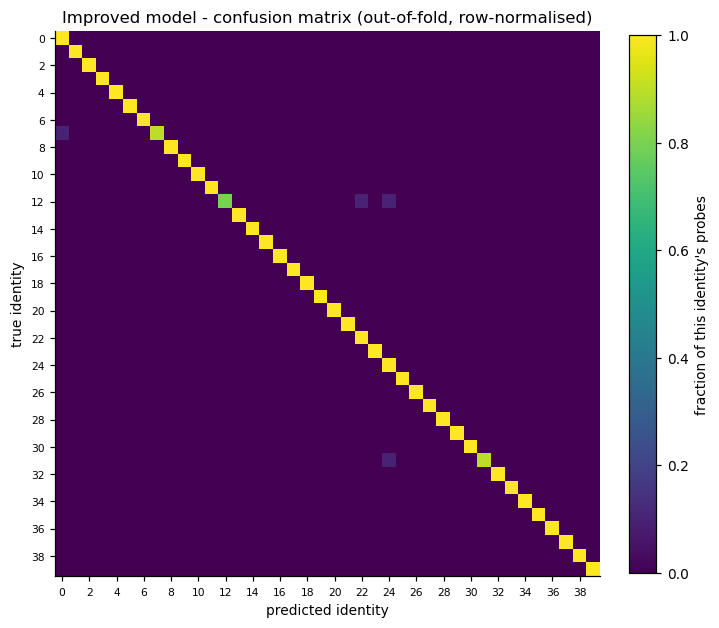

Most frequent confusions (true -> predicted, count):
   id  12  ->  id  22   x1
   id  12  ->  id  24   x1
   id   7  ->  id   0   x1
   id  31  ->  id  24   x1


In [15]:
m_impr = identification_metrics(y, oof_pred, oof_score, CLASSES)
print_metrics(f"IMPROVED  PCA->LDA->RBF-SVM  [{N_SPLITS}-fold out-of-fold, "
              f"{N_AUG}x augmentation]", m_impr)
print(f"  fold-to-fold std   {fold_df['accuracy'].std(ddof=1):.4f}")

cm_impr = plot_confusion(y, oof_pred, CLASSES,
                         "Improved model - confusion matrix (out-of-fold, row-normalised)",
                         save="09_improved_confusion")

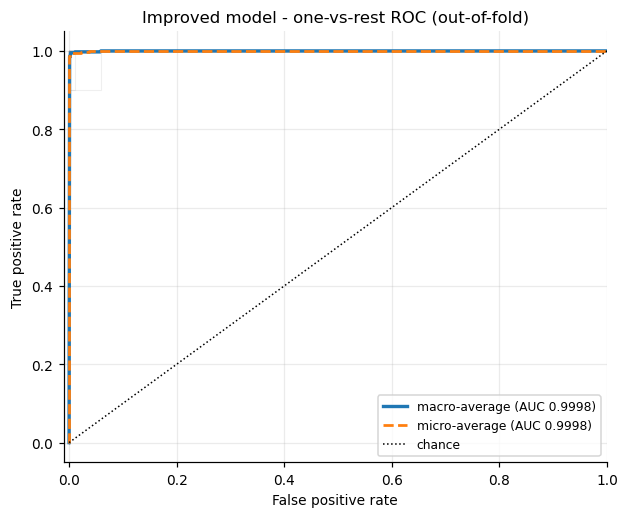

macro AUC 0.9998 | micro AUC 0.9998 | hardest identities: id 12 (0.994), id 31 (0.999), id 0 (1.000)


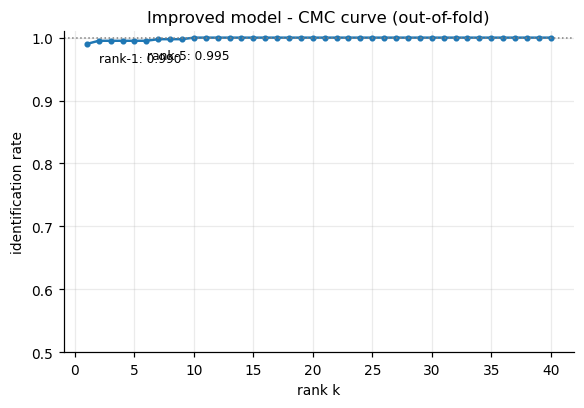

rank-1 0.9900 | rank-5 0.9950 | mean rank of the true identity 1.04


In [16]:
roc_impr = plot_multiclass_roc(y, oof_score, CLASSES,
                               "Improved model - one-vs-rest ROC (out-of-fold)",
                               save="10_improved_roc")

ranks_impr, cmc_impr = plot_cmc(y, oof_score, CLASSES,
                                "Improved model - CMC curve (out-of-fold)",
                                save="11_improved_cmc")

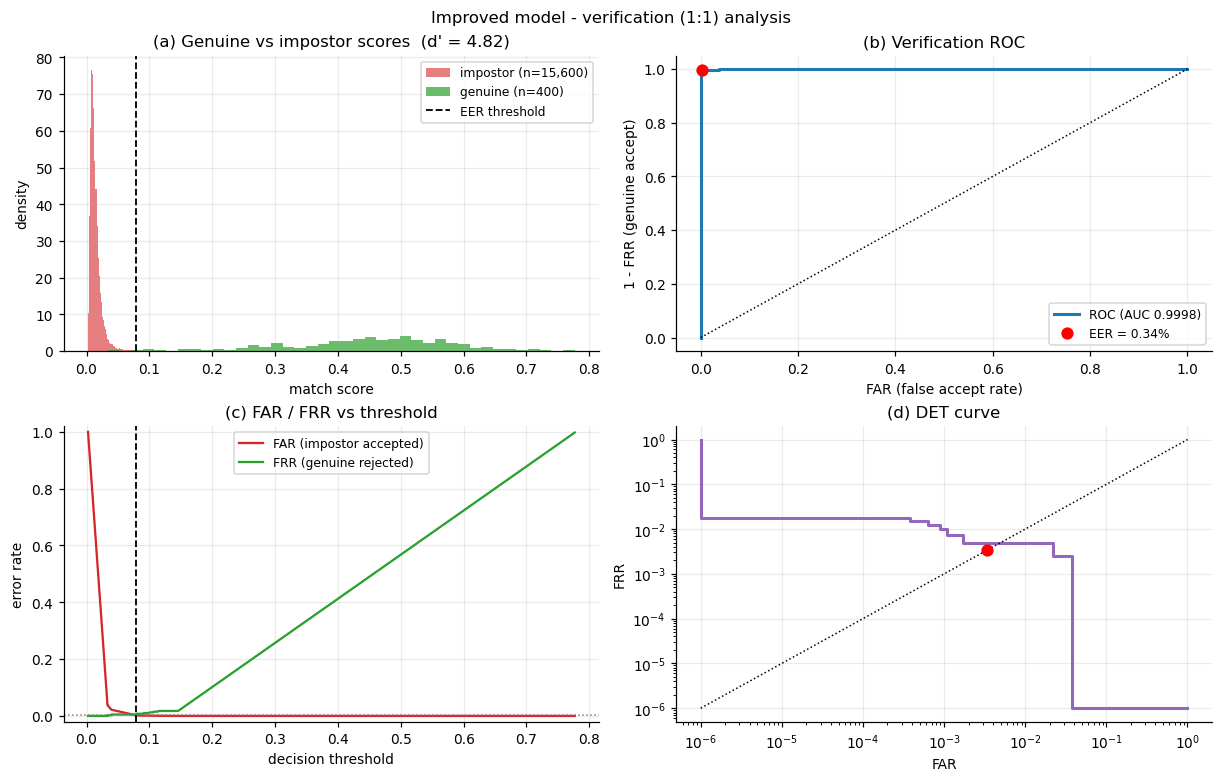

  EER              0.34%   (threshold 0.0793)
  verification AUC 0.9998   d-prime 4.82
  FRR @ FAR= 10.0% :   0.00%
  FRR @ FAR=  1.0% :   0.50%
  FRR @ FAR=  0.1% :   1.00%


In [17]:
gen_impr, imp_impr = verification_scores(y, oof_score, CLASSES)
ver_impr = plot_verification(gen_impr, imp_impr,
                             "Improved model - verification (1:1) analysis",
                             save="12_improved_verification")

RESULTS[f"Improved (PCA+LDA+SVM, {N_SPLITS}-fold)"] = {**m_impr, **roc_impr, **ver_impr}

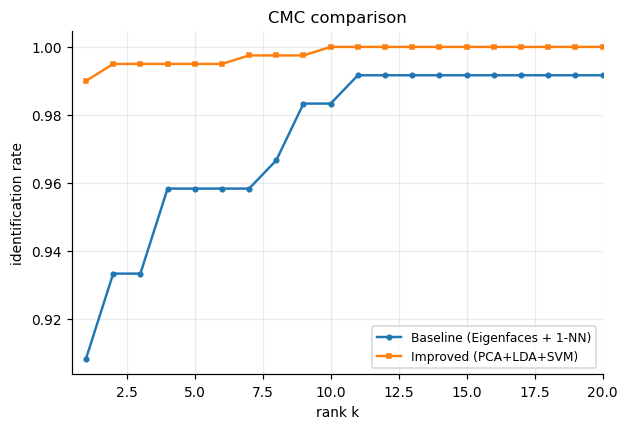

In [18]:
# ---- Side-by-side CMC: the clearest single picture of the improvement -----------------
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ks = np.arange(1, len(CLASSES) + 1)
ax.plot(ks, cmc_base, marker="o", ms=3, lw=1.6, label="Baseline (Eigenfaces + 1-NN)")
ax.plot(ks, cmc_impr, marker="s", ms=3, lw=1.6, label="Improved (PCA+LDA+SVM)")
ax.set_xlabel("rank k"); ax.set_ylabel("identification rate")
ax.set_title("CMC comparison"); ax.legend(fontsize=8); ax.set_xlim(0.5, 20)
savefig(fig, "13_cmc_comparison"); plt.show()

## Part 10 - Open-set identification: rejecting people who were never enrolled

Everything so far has been **closed-set**: every probe belonged to someone enrolled, so the
system only had to decide *which* enrolled person. A real door lock, phone unlock or watchlist
system faces people who are in no gallery at all, and a closed-set classifier will happily
assign every one of them to its best-matching enrolled identity. Accuracy stays high and the
system is wide open.

The protocol here is deliberately **subject-disjoint**: 32 identities are enrolled, the other
8 are never seen during training and appear only as impostors. The decision becomes

$$\text{accept identity } \hat{c} \quad\text{iff}\quad \max_c P(c \mid p) \ge \tau$$

and the figure of merit is the **Detection and Identification Rate (DIR)** at a given FAR:
the fraction of genuine probes that are both *above threshold* and *correctly identified*,
while impostors are accepted at most FAR of the time.

In [19]:
rng_os = np.random.default_rng(SEED)
perm        = rng_os.permutation(CLASSES)
known_ids   = np.sort(perm[:N_KNOWN_OPENSET])      # enrolled population
unknown_ids = np.sort(perm[N_KNOWN_OPENSET:])      # impostors -- never seen in training

enrol_idx, known_probe_idx = [], []
for c in known_ids:
    rows = rng_os.permutation(np.flatnonzero(y == c))
    enrol_idx.extend(rows[:7])                     # 7 enrolment images per known identity
    known_probe_idx.extend(rows[7:])               # 3 genuine probes per known identity
enrol_idx         = np.array(enrol_idx)
known_probe_idx   = np.array(known_probe_idx)
unknown_probe_idx = np.flatnonzero(np.isin(y, unknown_ids))

# Train on the enrolled population only (augmented, same recipe as Part 8)
X_en, y_en = (augment_batch(images[enrol_idx], y[enrol_idx], n_aug=N_AUG,
                            rng=np.random.default_rng(SEED))
              if N_AUG > 0 and not FAST_MODE else (images[enrol_idx], y[enrol_idx]))
X_en = X_en.reshape(len(X_en), -1)

os_model = build_improved_pipeline(probability=True)
os_model.fit(X_en, y_en)

P_known   = os_model.predict_proba(X[known_probe_idx])
P_unknown = os_model.predict_proba(X[unknown_probe_idx])
score_known,   pred_known   = P_known.max(axis=1), os_model.classes_[P_known.argmax(axis=1)]
score_unknown                = P_unknown.max(axis=1)
correct_known                = (pred_known == y[known_probe_idx])

print(f"enrolled identities : {len(known_ids)}   (enrolment images {len(enrol_idx)})")
print(f"genuine probes      : {len(known_probe_idx)}")
print(f"impostor probes     : {len(unknown_probe_idx)}  "
      f"(identities {unknown_ids.tolist()} -- never seen in training)")
print(f"closed-set accuracy on genuine probes (no threshold): {correct_known.mean():.4f}")
print(f"WITHOUT a threshold the system accepts {len(unknown_probe_idx)}/"
      f"{len(unknown_probe_idx)} impostors -- FAR = 100%")

enrolled identities : 32   (enrolment images 224)
genuine probes      : 96
impostor probes     : 80  (identities [1, 2, 8, 12, 13, 14, 33, 38] -- never seen in training)
closed-set accuracy on genuine probes (no threshold): 1.0000
WITHOUT a threshold the system accepts 80/80 impostors -- FAR = 100%


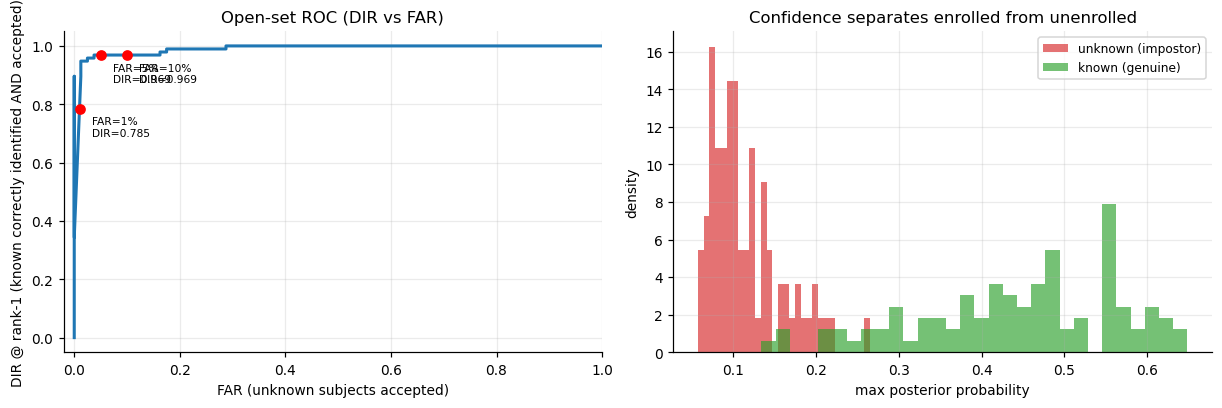

DIR @ FAR= 1% : 0.7854
DIR @ FAR= 5% : 0.9688
DIR @ FAR=10% : 0.9688
open-set EER  : 3.96%  at threshold 0.2125

The gap between closed-set accuracy and DIR@FAR=1% is the cost of having to say 'I don't know' -- and it is the number an access-control deployment lives or dies by.


In [20]:
# ---- Sweep the acceptance threshold ---------------------------------------------------
taus = np.unique(np.concatenate([score_known, score_unknown, [0.0, 1.0]]))
far  = np.array([(score_unknown >= t).mean() for t in taus])              # impostors let in
dir_ = np.array([((score_known >= t) & correct_known).mean() for t in taus])  # genuine ok
frr  = np.array([(score_known < t).mean() for t in taus])                 # genuine locked out

order = np.argsort(far)
def dir_at(target_far):
    return float(np.interp(target_far, far[order], dir_[order]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(far[order], dir_[order], lw=2, color="tab:blue")
for t in (0.01, 0.05, 0.10):
    ax[0].plot(t, dir_at(t), "ro", ms=6)
    ax[0].annotate(f"FAR={t:.0%}\nDIR={dir_at(t):.3f}", (t, dir_at(t)),
                   textcoords="offset points", xytext=(8, -18), fontsize=7)
ax[0].set_xlabel("FAR (unknown subjects accepted)")
ax[0].set_ylabel("DIR @ rank-1 (known correctly identified AND accepted)")
ax[0].set_title("Open-set ROC (DIR vs FAR)"); ax[0].set_xlim(-0.02, 1.0)

ax[1].hist(score_unknown, bins=30, density=True, alpha=0.65, color="tab:red",
           label="unknown (impostor)")
ax[1].hist(score_known, bins=30, density=True, alpha=0.65, color="tab:green",
           label="known (genuine)")
ax[1].set_xlabel("max posterior probability"); ax[1].set_ylabel("density")
ax[1].set_title("Confidence separates enrolled from unenrolled"); ax[1].legend(fontsize=8)
savefig(fig, "14_openset"); plt.show()

print(f"DIR @ FAR= 1% : {dir_at(0.01):.4f}")
print(f"DIR @ FAR= 5% : {dir_at(0.05):.4f}")
print(f"DIR @ FAR=10% : {dir_at(0.10):.4f}")
i_eer = int(np.nanargmin(np.abs(far - frr)))
print(f"open-set EER  : {(far[i_eer]+frr[i_eer])/2*100:.2f}%  at threshold {taus[i_eer]:.4f}")
print("\nThe gap between closed-set accuracy and DIR@FAR=1% is the cost of having to say "
      "'I don't know' -- and it is the number an access-control deployment lives or dies by.")

## Part 11 - Error analysis

Aggregate metrics tell you *how much* the system fails; these plots tell you *where*, which
is the part you can act on.

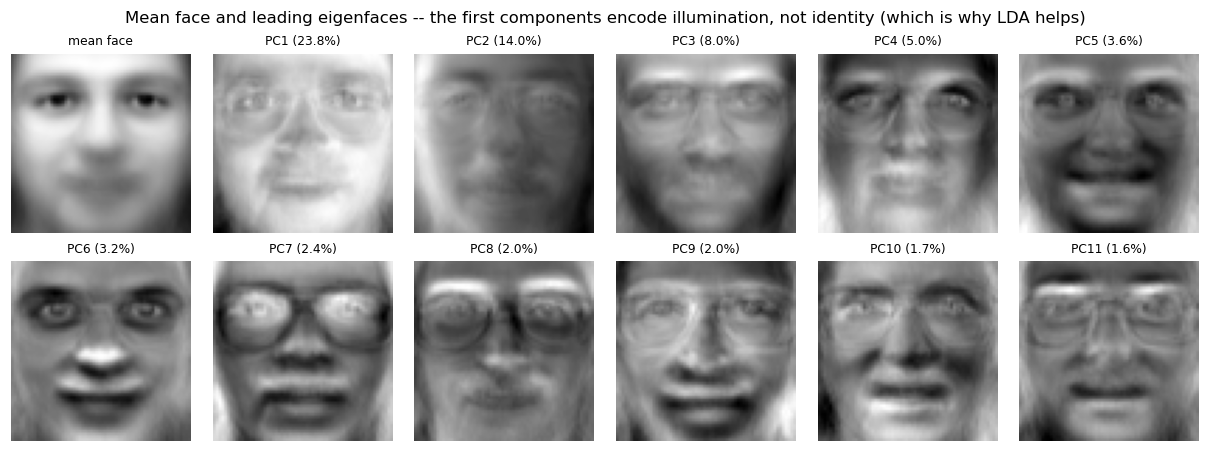

In [21]:
# ---- What the model actually looks at: mean face + leading eigenfaces -----------------
pca_vis = PCA(n_components=11, svd_solver="randomized", random_state=SEED).fit(X)
panels  = [X.mean(axis=0)] + list(pca_vis.components_)
titles  = ["mean face"] + [f"PC{i+1} ({v:.1%})"
                           for i, v in enumerate(pca_vis.explained_variance_ratio_)]
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, img, ttl in zip(axes.ravel(), panels, titles):
    ax.imshow(img.reshape(H, W), cmap="gray"); ax.set_title(ttl, fontsize=8); ax.axis("off")
fig.suptitle("Mean face and leading eigenfaces -- the first components encode illumination, "
             "not identity (which is why LDA helps)")
savefig(fig, "15_eigenfaces"); plt.show()

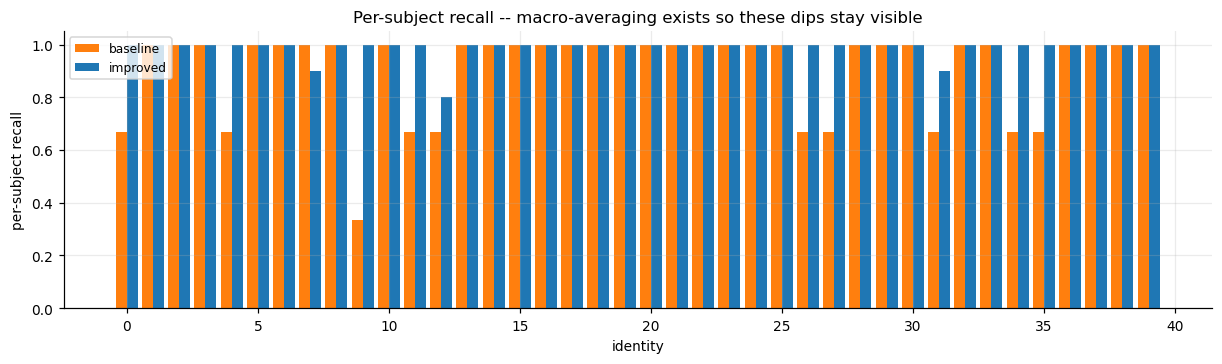

Hardest identities for the improved model: id 12 (recall 0.80), id 7 (recall 0.90), id 31 (recall 0.90), id 0 (recall 1.00), id 23 (recall 1.00)


In [22]:
# ---- Which subjects are hard? ---------------------------------------------------------
rec_base = np.array([(y_pred_base[y_test == c] == c).mean() if (y_test == c).any() else np.nan
                     for c in CLASSES])
rec_impr = np.array([(oof_pred[y == c] == c).mean() for c in CLASSES])

fig, ax = plt.subplots(figsize=(11, 3.2))
w = 0.42
ax.bar(CLASSES - w/2, rec_base, w, label="baseline", color="tab:orange")
ax.bar(CLASSES + w/2, rec_impr, w, label="improved", color="tab:blue")
ax.set_xlabel("identity"); ax.set_ylabel("per-subject recall"); ax.set_ylim(0, 1.05)
ax.set_title("Per-subject recall -- macro-averaging exists so these dips stay visible")
ax.legend(fontsize=8)
savefig(fig, "16_per_subject_recall"); plt.show()

hard = CLASSES[np.argsort(rec_impr)][:5]
print("Hardest identities for the improved model: " +
      ", ".join(f"id {c} (recall {rec_impr[list(CLASSES).index(c)]:.2f})" for c in hard))

4 misclassified probes out of 400 (1.00% error rate)


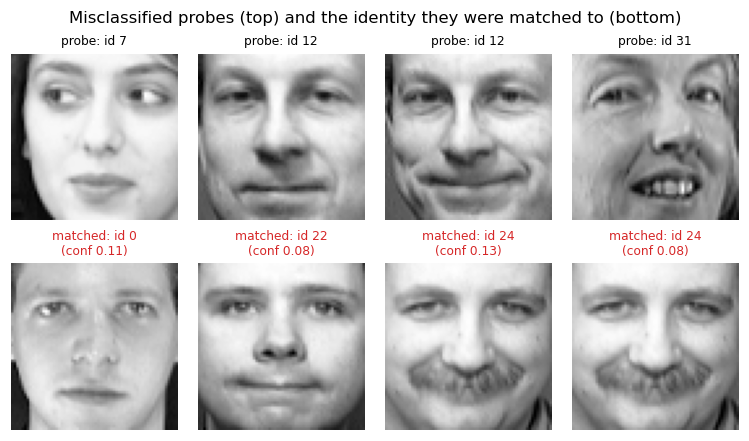

confidence on errors : mean 0.100, max 0.132
confidence on correct: mean 0.453


In [23]:
# ---- Look at the actual mistakes ------------------------------------------------------
errors = np.flatnonzero(oof_pred != y)
print(f"{len(errors)} misclassified probes out of {len(y)} "
      f"({len(errors)/len(y):.2%} error rate)")

if len(errors):
    show = errors[:6]
    fig, axes = plt.subplots(2, len(show), figsize=(1.7*len(show), 3.9))
    axes = np.atleast_2d(axes)
    for j, e in enumerate(show):
        conf = oof_score[e].max()
        axes[0, j].imshow(images[e], cmap="gray"); axes[0, j].axis("off")
        axes[0, j].set_title(f"probe: id {y[e]}", fontsize=8)
        match = np.flatnonzero(y == oof_pred[e])[0]
        axes[1, j].imshow(images[match], cmap="gray"); axes[1, j].axis("off")
        axes[1, j].set_title(f"matched: id {oof_pred[e]}\n(conf {conf:.2f})",
                             fontsize=8, color="tab:red")
    fig.suptitle("Misclassified probes (top) and the identity they were matched to (bottom)")
    savefig(fig, "17_misclassified"); plt.show()

    # High-confidence errors are the dangerous ones: a threshold will not catch them.
    conf_err = oof_score[errors].max(axis=1)
    print(f"confidence on errors : mean {conf_err.mean():.3f}, max {conf_err.max():.3f}")
    print(f"confidence on correct: mean {oof_score[oof_pred == y].max(axis=1).mean():.3f}")
else:
    print("No misclassifications in the out-of-fold predictions.")

## Part 12 - Model comparison, deployment cost, and saving the system

A caveat to read the table with: the baseline row comes from a single 120-probe hold-out,
the improved row from 400 out-of-fold probes. The improved protocol is the more trustworthy
estimate, and it is also the harder one - the single split got the easier job.

                                        accuracy  precision_macro  recall_macro  f1_macro  rank5_accuracy  macro_auc  verification_auc   eer_%  dprime
Baseline (Eigenfaces + 1-NN, hold-out)    0.9083           0.9388        0.9083    0.9059          0.9583     0.9900            0.9643  9.2415  2.7009
Improved (PCA+LDA+SVM, 5-fold)            0.9900           0.9913        0.9900    0.9899          0.9950     0.9998            0.9998  0.3365  4.8166


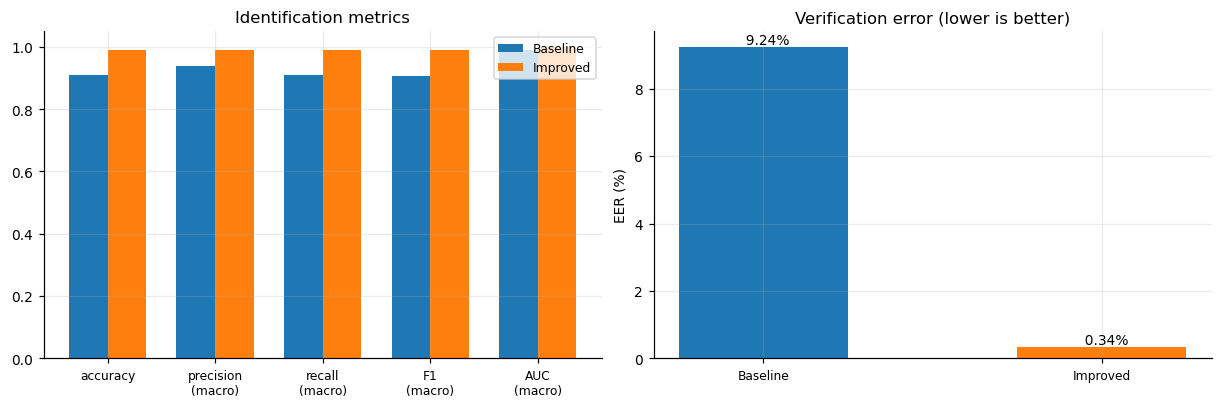

In [24]:
KEYS = ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro",
        "rank1_accuracy", "rank5_accuracy", "macro_auc", "micro_auc",
        "verification_auc", "eer", "dprime"]
comparison = pd.DataFrame({name: {k: res.get(k, np.nan) for k in KEYS}
                           for name, res in RESULTS.items()}).T
comparison["eer_%"] = comparison["eer"] * 100
display_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro",
                "rank5_accuracy", "macro_auc", "verification_auc", "eer_%", "dprime"]
print(comparison[display_cols].round(4).to_string())

labels_cmp = list(RESULTS.keys())
metrics_cmp = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "macro_auc"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
xs, w = np.arange(len(metrics_cmp)), 0.36
for i, name in enumerate(labels_cmp):
    ax[0].bar(xs + (i - 0.5) * w, [RESULTS[name][m] for m in metrics_cmp], w,
              label=name.split(" (")[0])
ax[0].set_xticks(xs)
ax[0].set_xticklabels(["accuracy", "precision\n(macro)", "recall\n(macro)",
                       "F1\n(macro)", "AUC\n(macro)"], fontsize=8)
ax[0].set_ylim(0, 1.05); ax[0].set_title("Identification metrics"); ax[0].legend(fontsize=8)
for i, name in enumerate(labels_cmp):
    ax[1].bar(i, RESULTS[name]["eer"] * 100, 0.5)
    ax[1].text(i, RESULTS[name]["eer"] * 100, f"  {RESULTS[name]['eer']*100:.2f}%",
               ha="center", va="bottom", fontsize=9)
ax[1].set_xticks(range(len(labels_cmp)))
ax[1].set_xticklabels([n.split(" (")[0] for n in labels_cmp], fontsize=8)
ax[1].set_ylabel("EER (%)"); ax[1].set_title("Verification error (lower is better)")
savefig(fig, "18_model_comparison"); plt.show()

In [25]:
# ---- Train the deployment model on all available data ---------------------------------
# Hyperparameters: the setting the inner searches chose most often across the outer folds.
from collections import Counter
vote = Counter(tuple(sorted(p.items())) for p in fold_params)
best_params = dict(vote.most_common(1)[0][0])
print(f"hyperparameters selected in {vote.most_common(1)[0][1]}/{N_SPLITS} folds: {best_params}")

X_all, y_all = (augment_batch(images, y, n_aug=N_AUG, rng=np.random.default_rng(SEED))
                if N_AUG > 0 and not FAST_MODE else (images, y))
X_all = X_all.reshape(len(X_all), -1)

final_model = build_improved_pipeline(probability=True)
final_model.set_params(**{**best_params, "svm__probability": True})
t0 = time.perf_counter(); final_model.fit(X_all, y_all); enrol_time = time.perf_counter() - t0

# ---- Deployment cost: template size and matching latency ------------------------------
embedding = final_model[:-1].transform(X[:1])          # everything before the classifier
template_bytes = embedding.shape[1] * 4                # float32 template
raw_bytes      = X.shape[1] * 4

probe = X[:1]
final_model.predict(probe)                             # warm-up (first call pays lazy init)
t0 = time.perf_counter()
for _ in range(100):
    final_model.predict(probe)
match_ms = (time.perf_counter() - t0) / 100 * 1000

print(f"\n--- deployment profile ---")
print(f"enrolment (fit on {len(X_all)} images) : {enrol_time:.2f} s")
print(f"template dimension                     : {embedding.shape[1]}")
print(f"template size                          : {template_bytes} B "
      f"(raw image {raw_bytes} B -> {raw_bytes/template_bytes:.0f}x smaller)")
print(f"single-probe matching latency          : {match_ms:.2f} ms "
      f"(~{1000/match_ms:.0f} probes/s)")
print(f"gallery of 10,000 users would need     : "
      f"{template_bytes*10000/1e6:.1f} MB of template storage")

hyperparameters selected in 3/5 folds: {'pca__n_components': 120, 'svm__C': 1.0, 'svm__gamma': 'scale'}

--- deployment profile ---
enrolment (fit on 1200 images) : 0.53 s
template dimension                     : 39
template size                          : 156 B (raw image 16384 B -> 105x smaller)
single-probe matching latency          : 1.01 ms (~995 probes/s)
gallery of 10,000 users would need     : 1.6 MB of template storage


In [26]:
# ---- Persist the model and everything needed to reproduce / audit this run -------------
model_path = MODEL_DIR / "face_biometric_model.joblib"
joblib.dump(final_model, model_path)

metadata = {
    "created":            time.strftime("%Y-%m-%d %H:%M:%S"),
    "dataset":            DATA_SOURCE,
    "n_identities":       int(len(CLASSES)),
    "n_images":           int(len(y)),
    "image_shape":        [int(H), int(W)],
    "seed":               SEED,
    "pipeline":           [name for name, _ in final_model.steps],
    "hyperparameters":    {k: str(v) for k, v in best_params.items()},
    "augmentation_factor": 0 if FAST_MODE else N_AUG,
    "cv_folds":           N_SPLITS,
    "template_dim":       int(embedding.shape[1]),
    "metrics_oof":        {k: float(m_impr[k]) for k in
                           ("accuracy", "precision_macro", "recall_macro", "f1_macro",
                            "rank1_accuracy", "rank5_accuracy")},
    "macro_auc":          float(roc_impr["macro_auc"]),
    "eer":                float(ver_impr["eer"]),
    "eer_threshold":      float(ver_impr["eer_threshold"]),
    "sklearn_version":    sklearn.__version__,
}
meta_path = MODEL_DIR / "model_card.json"
meta_path.write_text(json.dumps(metadata, indent=2))

comparison.to_csv(MODEL_DIR / "results_comparison.csv")
fold_df.to_csv(MODEL_DIR / "cv_folds.csv", index=False)

print(f"model     -> {model_path}  ({model_path.stat().st_size/1e6:.2f} MB)")
print(f"model card-> {meta_path}")
print(f"figures   -> {FIG_DIR.resolve()}  ({len(list(FIG_DIR.glob('*.png')))} files)")
print("\n" + json.dumps(metadata, indent=2)[:900] + "\n...")

# ---- Reload and verify the saved artefact actually works ------------------------------
reloaded = joblib.load(model_path)
assert (reloaded.predict(X[:20]) == final_model.predict(X[:20])).all()
print("\nreload check: OK -- saved model reproduces identical predictions")

model     -> models/face_biometric_model.joblib  (3.02 MB)
model card-> models/model_card.json
figures   -> /Users/bli1/Documents/project/lab/lab-practice/biometrics/figures  (18 files)

{
  "created": "2026-10-12 11:34:41",
  "dataset": "olivetti",
  "n_identities": 40,
  "n_images": 400,
  "image_shape": [
    64,
    64
  ],
  "seed": 42,
  "pipeline": [
    "scaler",
    "pca",
    "lda",
    "svm"
  ],
  "hyperparameters": {
    "pca__n_components": "120",
    "svm__C": "1.0",
    "svm__gamma": "scale"
  },
  "augmentation_factor": 2,
  "cv_folds": 5,
  "template_dim": 39,
  "metrics_oof": {
    "accuracy": 0.99,
    "precision_macro": 0.9912878787878789,
    "recall_macro": 0.99,
    "f1_macro": 0.9899369636211741,
    "rank1_accuracy": 0.99,
    "rank5_accuracy": 0.995
  },
  "macro_auc": 0.9998012820512819,
  "eer": 0.0033653846153846177,
  "eer_threshold": 0.07931454874996627,
  "sklearn_version": "1.6.1"
}
...

reload check: OK -- saved model reproduces identical predictions


## Part 13 - Limitations, privacy, and where to take this next

### Read the numbers with these caveats

1. **The dataset is easy.** 40 cooperative subjects, controlled lighting, dark uniform
   background, frontal-ish poses, 64x64. Accuracy near 1.0 here says the pipeline is wired
   correctly - it says nothing about in-the-wild performance. The same code on LFW or
   IJB-C will drop sharply, and that drop is the honest measurement.
2. **The resolution of the error estimate is limited.** 400 probes means accuracy moves in
   steps of 0.25 points. Quoting four decimal places, or claiming a 0.5-point difference
   between two models, is over-reading the data. The per-fold standard deviation in Part 8 is
   the number to quote alongside the mean.
3. **FAR = 0.1% is at the edge of what this data can measure.** There are ~15,600 impostor
   comparisons, so a 0.1% FAR estimate rests on roughly 15 events. Reliable low-FAR operating
   points need orders of magnitude more impostor pairs.
4. **Identification and verification were measured from the same score matrix.** That is a
   legitimate and common construction, but a production verification system would be measured
   on genuine/impostor pairs drawn from *subject-disjoint* data - the Part 10 protocol
   extended to 1:1 comparisons.
5. **No demographic breakdown.** Face recognition error rates are well documented to vary by
   skin tone, age and sex (NIST FRVT Part 3). This dataset carries no demographic labels, so
   no fairness audit is possible here - which is itself a finding worth stating, not an
   omission to leave silent.

### Privacy and template protection

Biometrics are the one credential that cannot be reissued. The `joblib` file written in Part
12 contains PCA and LDA bases fitted on real faces, and PCA components are **invertible** -
an attacker with the model and a template can reconstruct a recognisable approximation of the
enrolled face. Treat the model file and any stored templates as biometric data, not as build
artefacts:

* **Never store raw templates in the clear.** Use a cancelable-biometric transform (BioHashing,
  random projection with a user-specific key) or a fuzzy-vault / fuzzy-extractor scheme so a
  compromised database can be revoked and re-enrolled under a new key.
* **Separate the key from the template** so that a dump of one is not sufficient.
* **Legal footing matters.** Illinois BIPA, Texas CUBI and GDPR Art. 9 treat biometric
  identifiers as a special category with consent and retention duties attached. A research
  prototype that is later demoed on real people inherits those obligations.
* **Presentation-attack detection is absent here.** Every model in this notebook can be
  defeated by holding up a printed photograph. Anti-spoofing (ISO/IEC 30107) is a separate
  component, not something the matcher provides.

### Natural extensions

| Direction | Change |
|---|---|
| Harder data | Swap `fetch_olivetti_faces` for `fetch_lfw_people(min_faces_per_person=20, resize=0.5)` - nothing downstream changes |
| Stronger features | Replace PCA+LDA with a pretrained embedding (FaceNet / ArcFace / `dlib` 128-D) and keep the entire evaluation toolkit |
| Other modalities | Fingerprint (FVC2004), iris (CASIA-Iris), gait, keystroke dynamics - swap the loader, reuse Parts 4-12 unchanged |
| Score fusion | Combine two matchers at score level (weighted sum, likelihood ratio) and compare EERs |
| Robustness | Re-run the pipeline under occlusion, blur and JPEG compression to produce a degradation curve |
| Spoof resistance | Add a presentation-attack dataset and report APCER / BPCER next to FAR / FRR |